# 03 · Part 1: Predicting Sale Prices (an Automated Valuation Model)

An **automated valuation model (AVM)** estimates what a home will sell for from its characteristics and
location. Lenders use AVMs to approve loans, iBuyers to make offers, and Zillow's Zestimate is one. The
industry grades them with a few standard numbers, and so does this notebook:

| Metric | Meaning |
|---|---|
| **MdAPE** | median absolute % error between predicted and actual price |
| **PPE10 / PPE20** | share of homes predicted within ±10% / ±20% of the sale price |
| **bias** | median signed error (positive = model over-predicts) |

**The question:** how close can public data get, and does machine learning beat the methods people
already use (comparable sales, the county appraiser)?

All model code is in `src/price_model.py`.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import price_model as pm
from plotting import *

warnings.filterwarnings("ignore", category=FutureWarning)
use_style()
pd.set_option("display.width", 200)
FIG = ROOT / "figures"

d = pm.load_model_data()
print(f"{len(d):,} sales  ({d['sale_date'].min():%b %Y} – {d['sale_date'].max():%b %Y})")

97,248 sales  (Jan 2019 – Dec 2025)


**Sample:** clean single-family sales from Phase 2, minus homes sold storm-damaged (a damaged home's price
reflects repair costs the data can't see) and the ~4.5% without map coordinates.

**Features** (all known *before* the sale):
- *structure:* heated and total area, lot size, year built and effective (renovation-adjusted) year, beds, baths,
  stories, pool, dock, seawall, garage, appraiser quality grade and construction class
- *location:* latitude/longitude, waterfront type, block group and market area, 2008 and current flood zone
- *market timing:* months since Jan 2019

**Deliberately excluded:** the county's assessed value (tested separately in section 5).

## 1. Evaluation design: forecast the future, don't interpolate the past

The common mistake is a **random** train/test split: the model then sees sales from the same months it's
tested on, so it already "knows" the market level. A real AVM values homes *today* using *past* sales.

- **Train:** 2019–2023 → **validate on 2024** (choose settings) → retrain on 2019–2024 → **test once on 2025**
- At test time the market clock is **frozen** at the last training month. The model must price 2025 homes
  with what it knew in December 2024, as a lender would.

Four models, from simplest to most complex:

| Model | How it works |
|---|---|
| **Comps** | median $/heated sq ft of the last 12 months' sales in the home's block group × its heated area: the realtor's rule of thumb |
| **County appraisal** | the appraiser's Jan-1 "just value" × the recent median sale-to-appraisal ratio |
| **Linear hedonic** | ridge regression of log price on all features + block-group and quarter dummies |
| **Gradient boosting** | an ensemble of decision trees (`HistGradientBoostingRegressor`) that learns non-linear effects and interactions |

## 2. Validation year (2024): choosing settings

In [2]:
tr, va = pm.time_split(d, "2024-01-01", "2025-01-01")
grid = {
    "63 leaves (chosen)":                 dict(max_leaf_nodes=63),
    "31 leaves":                          dict(max_leaf_nodes=31),
    "127 leaves, min 40 per leaf":        dict(max_leaf_nodes=127, min_samples_leaf=40),
    "63 leaves, min 50, slower learning": dict(max_leaf_nodes=63, min_samples_leaf=50, learning_rate=0.03),
}
tuning = pd.DataFrame({k: pm.metrics(va["log_price"], pm.GBModel(**p).fit(tr).predict(va)) for k, p in grid.items()}).T
tuning.round(2)

,MdAPE %,within 10% (PPE10),within 20% (PPE20),bias % (median),R² (log price)
63 leaves (chosen),8.60,56.32,82.75,1.67,0.9
31 leaves,8.71,55.83,82.63,1.76,0.9
"127 leaves, min 40 per leaf",8.61,55.71,81.95,1.98,0.9
"63 leaves, min 50, slower learning",8.58,56.22,82.59,1.83,0.9


Differences are small: all four settings land within a few tenths of a point of MdAPE. 63 leaves is chosen.
*(Reproducibility note: results were initially slightly different on every run. The cause was the block-group
target encoder, which shuffles its cross-fitting folds with an unseeded random generator by default. Seeding
the folds made every run identical.)*
(An earlier version of the model, with native categorical features, preferred 31 leaves; the setting was
re-chosen after the rebuild described in section 7.) Ridge's penalty strength was checked the same way (α = 0.3 / 1 / 3 were within 0.05 points), so α = 1. Those are the settings in
`price_model.py`. **The 2025 test set was not used for any of these choices.**

In [3]:
val_scores, _ = pm.evaluate_all(tr, va)
val_scores.round(2)

,MdAPE %,within 10% (PPE10),within 20% (PPE20),bias % (median),R² (log price)
Comps ($/sq ft × size),13.88,37.85,64.72,2.64,0.78
County appraisal × ratio,9.00,54.36,78.73,4.47,0.86
Linear hedonic (ridge),10.56,48.08,76.38,3.56,0.87
Gradient boosting,8.60,56.32,82.75,1.67,0.90


## 3. Final test: 2025 sales, never seen during development

In [4]:
tr, te = pm.time_split(d, "2025-01-01", "2026-01-01")
scores, fitted = pm.evaluate_all(tr, te)
gb = fitted["Gradient boosting"]
te = te.assign(pred_gb=gb.predict(te))
te["err"] = pm.pct_error(te["log_price"], te["pred_gb"])
print(f"train n = {len(tr):,}   test n = {len(te):,}")
scores.round(2)

train n = 85,209   test n = 12,039


,MdAPE %,within 10% (PPE10),within 20% (PPE20),bias % (median),R² (log price)
Comps ($/sq ft × size),15.90,33.61,58.88,6.95,0.75
County appraisal × ratio,10.39,48.53,75.44,3.06,0.86
Linear hedonic (ridge),11.34,45.37,72.66,4.66,0.86
Gradient boosting,9.15,53.87,79.96,2.87,0.90


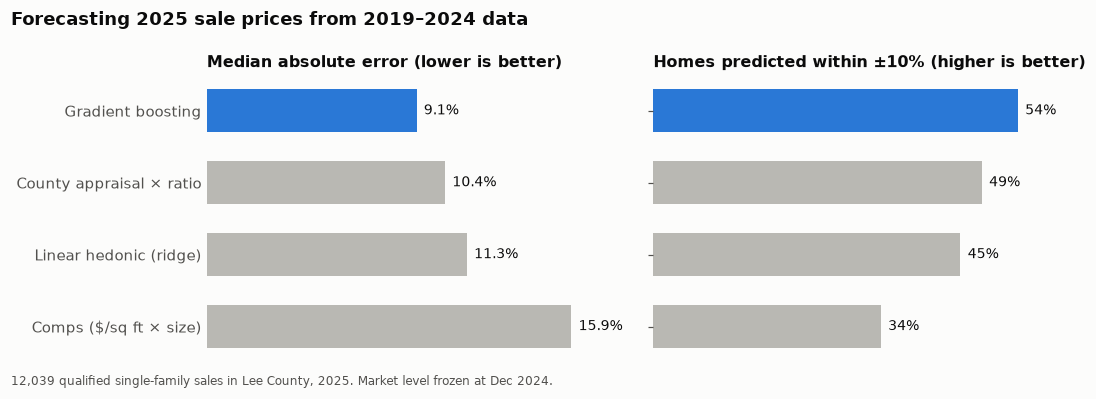

In [5]:
order = scores.sort_values("MdAPE %", ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, col, title, fmt in [(axes[0], "MdAPE %", "Median absolute error (lower is better)", "{:.1f}%"),
                            (axes[1], "within 10% (PPE10)", "Homes predicted within ±10% (higher is better)", "{:.0f}%")]:
    vals = scores.loc[order, col]
    colors = [C1 if n == "Gradient boosting" else "#b9b8b3" for n in order]
    ax.barh(range(len(vals)), vals, color=colors, height=0.6)
    for i, v in enumerate(vals):
        ax.text(v + vals.max() * 0.02, i, fmt.format(v), va="center", fontsize=9, color=INK)
    ax.set_title(title, fontsize=10.5); ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, vals.max() * 1.18); ax.set_xticks([])
    for s in ["left", "bottom"]: ax.spines[s].set_visible(False)
axes[0].set_yticks(range(len(order)), order); axes[0].tick_params(axis="y", length=0)
fig.suptitle("Forecasting 2025 sale prices from 2019–2024 data", x=0.01, ha="left", fontweight="bold", fontsize=12, color=INK)
source_note(fig, f"{len(te):,} qualified single-family sales in Lee County, 2025. Market level frozen at Dec 2024.")
save(fig, FIG / "03_model_scoreboard.png")

**Read:**
- **Gradient boosting wins on every metric**: about half of 2025 homes predicted within ±10%, and a ~9%
  median error, from public data only.
- **The county appraisal is the strongest benchmark.** That's no surprise: the appraiser has inspected the
  homes and has data we don't (condition, interior finishes). The model still beats it by roughly 1 point
  of MdAPE and 5 points of PPE10.
- **Comps are weakest.** $/sq ft for a whole block group ignores everything that makes one home differ from its
  neighbors: water, pool, age, lot.
- **Every model over-predicts (positive bias)**: 2025 prices kept falling after the December 2024 cutoff. A
  frozen market clock can't see that. Section 6 shows the error growing month by month.

For context: Zillow publishes a national median error of roughly 7% for off-market homes, using MLS listing data
(photos, descriptions, list prices) that this project doesn't have.

## 4. Why the time split matters: random splits flatter the model

In [6]:
shuffled = d.sample(frac=1, random_state=0)
n_tr = int(len(shuffled) * 0.85)
r_tr, r_te = shuffled.iloc[:n_tr], shuffled.iloc[n_tr:]
random_split = pm.metrics(r_te["log_price"], pm.GBModel().fit(r_tr).predict(r_te))
pd.DataFrame({"random 85/15 split (2019–2025 mixed)": random_split,
              "time split (test = 2025)": scores.loc["Gradient boosting"]}).T.round(2)

,MdAPE %,within 10% (PPE10),within 20% (PPE20),bias % (median),R² (log price)
random 85/15 split (2019–2025 mixed),7.87,59.84,85.36,-1.44,0.92
time split (test = 2025),9.15,53.87,79.96,2.87,0.90


The same model looks noticeably better under a random split, because it gets to learn from test-period sales
and sees no market drift. That's the number a careless project would report. The time-split number is
the honest one.

## 5. The county appraisal: a strong benchmark, but a poor feature

Natural idea: feed the appraiser's value into the model as a feature. It made things **worse** in validation.
The reason is visible in how sales compare to appraisals year by year:

In [7]:
ratio = (d.loc[d["just_value"] > 0].assign(r=lambda x: x["sale_price"] / x["just_value"])
          .groupby("sale_yr")["r"].median().rename("median sale price ÷ appraised value"))
ratio.to_frame().T.round(2)

sale_yr,2019,2020,2021,2022,2023,2024,2025
median sale price ÷ appraised value,1.28,1.32,1.52,1.43,1.27,1.21,1.18


In [8]:
class GBWithAppraisal(pm.GBModel):
    """GB + appraised value, adjusted by the PREVIOUS year's sale/appraisal ratio (known at forecast time)."""
    def _X(self, df, fit=False):
        X = super()._X(df, fit)
        lag = df["sale_yr"].map(lambda y: np.log(ratio.get(y - 1, ratio.iloc[0])))
        X["log_appraisal_adj"] = np.log(df["just_value"].where(df["just_value"] > 0)) + lag
        return X

tr_v, va_v = pm.time_split(d, "2024-01-01", "2025-01-01")
pd.DataFrame({
    "gradient boosting": pm.metrics(va_v["log_price"], pm.GBModel().fit(tr_v).predict(va_v)),
    "+ appraised value": pm.metrics(va_v["log_price"], GBWithAppraisal().fit(tr_v).predict(va_v)),
}).T.round(2)

,MdAPE %,within 10% (PPE10),within 20% (PPE20),bias % (median),R² (log price)
gradient boosting,8.60,56.32,82.75,1.67,0.90
+ appraised value,9.34,52.78,82.48,-4.18,0.89


The appraisal is set on **January 1** using the **prior year's** sales, and Florida appraisers also deduct
roughly 15% for costs of sale. So the sale-to-appraisal ratio is never 1, and it swings with the market: 1.32 in
2020, **1.52** in the 2021 boom (appraisals far behind rising prices), down to 1.18 by 2025. A model trained across
those years learns an *average* relationship that's wrong for any particular year. Used on its own with
the most recent ratio, the appraisal is a good AVM; as a feature it adds noise. *(Validation year only: the
2025 test set was not used for this comparison.)*

## 6. Where the model struggles

In [9]:
seg = lambda col: te.groupby(col)["err"].agg(
    MdAPE=lambda e: 100 * np.median(np.abs(e)), bias=lambda e: 100 * np.median(e), sales="size")
te["price band"] = pd.qcut(te["sale_price"], 5, labels=["bottom 20%", "20–40%", "40–60%", "60–80%", "top 20%"])
te["heated area"] = np.where(te["heated_imputed"] == 1, "imputed (new parcels)", "from GIS")
display(seg("price band").round(1))
display(seg("waterfront").reindex(["NONE", "LAKE", "GOLF", "CANAL", "CREEK", "RIVER", "BAY", "GULF"]).dropna().round(1))
display(seg("heated area").round(1))
seg("city").query("sales >= 150").sort_values("MdAPE").round(1)

,MdAPE,bias,sales
price band,,,
bottom 20%,13.7,10.6,2416
20–40%,7.0,3.2,2461
40–60%,8.4,1.8,2387
60–80%,8.4,2.6,2385
top 20%,10.5,-3.7,2390


,MdAPE,bias,sales
waterfront,,,
NONE,8.7,2.5,7718.0
LAKE,9.2,4.8,1946.0
GOLF,10.4,2.5,649.0
CANAL,10.5,3.5,1582.0
CREEK,14.8,-11.3,35.0
RIVER,15.3,-2.6,74.0
BAY,14.6,-14.4,35.0


,MdAPE,bias,sales
heated area,,,
from GIS,9.5,3.1,10029
imputed (new parcels),7.4,2.2,2010


,MdAPE,bias,sales
city,,,
LEHIGH ACRES,6.6,-0.1,938
CAPE CORAL,8.6,4.1,4582
ESTERO,9.1,4.2,885
BONITA SPRINGS,9.5,2.8,920
FORT MYERS,9.9,2.4,3367
NORTH FORT MYERS,11.1,3.4,633
ALVA,11.9,5.3,193


sale_date,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,2025-11-01,2025-12-01
bias,-1.4,-0.6,0.3,1.8,2.8,3.5,5.5,5.4,5.5,6.0,4.9,5.2
MdAPE,7.7,8.2,7.9,8.8,9.0,9.2,9.9,10.2,10.1,9.9,10.1,10.3


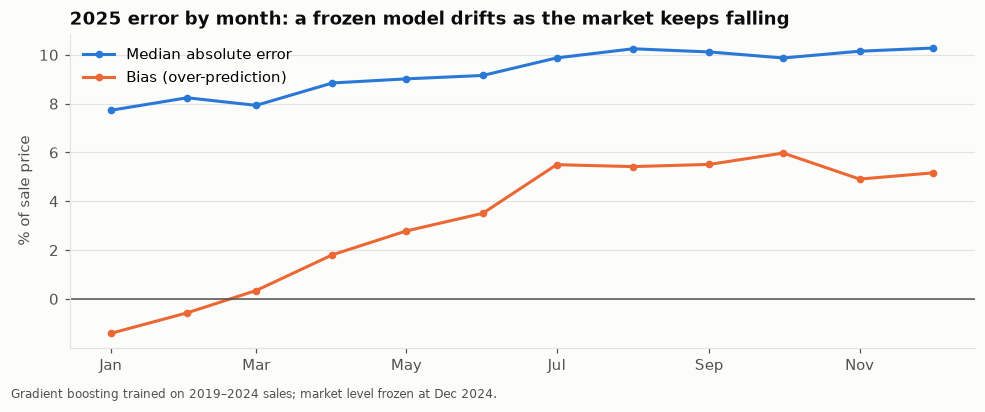

In [10]:
monthly = te.groupby("sale_date")["err"].agg(bias=lambda e: 100 * np.median(e), MdAPE=lambda e: 100 * np.median(np.abs(e)))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(monthly.index, monthly["MdAPE"], color=C1, marker="o", ms=4, label="Median absolute error")
ax.plot(monthly.index, monthly["bias"], color=C2, marker="o", ms=4, label="Bias (over-prediction)")
ax.axhline(0, color=INK2, lw=1)
ax.set_ylabel("% of sale price"); ax.legend(loc="upper left")
ax.set_title("2025 error by month: a frozen model drifts as the market keeps falling")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b"))
source_note(fig, "Gradient boosting trained on 2019–2024 sales; market level frozen at Dec 2024.")
save(fig, FIG / "03_error_drift_2025.png")
monthly.round(1).T

**Read:**
- **The bottom price band is hardest**: cheap homes have the most variable condition (fixer-uppers, older
  stock in Lehigh Acres and North Fort Myers), and condition isn't in public data. A $20k error is also a
  larger *percentage* on a $250k home.
- **Errors pull toward the middle:** the cheapest homes are over-predicted and the most expensive
  under-predicted, a classic sign that the features don't fully capture what makes a home unusual in either direction.
- **Rare, high-value waterfront** (bay, creek: a few dozen 2025 sales each) is under-predicted by double digits:
  few training examples, and the most expensive homes on the water. No Gulf-front homes sold in 2025.
- **Homes with imputed heated area** (parcels created after the 2024 GIS snapshot) are predicted *better* than
  the rest. They're mostly new construction, which is uniform and easy to price. This supports the Phase 2
  decision to impute them rather than drop them.
- **Drift:** bias rises over the year as 2025 prices keep slipping below the December 2024 level. In
  production an AVM is retrained monthly; this test shows what happens if it isn't.

## 7. What the model learned (SHAP)

**SHAP** splits each prediction into contributions from each feature: how much did *this home's* lot size
push its predicted price up or down, compared with the average home? Averaging the size of those
contributions over many homes ranks the features.

*Implementation note:* SHAP's fast tree algorithm mishandles scikit-learn's native categorical splits.
In a first version its values didn't add up to the model's predictions (off by up to 3 log points). The model
was rebuilt with all-numeric inputs (one-hot waterfront, target-encoded areas), and the check below confirms
the SHAP values now sum exactly to each prediction.

max |sum of SHAP values + base - prediction| = 5.9e-14


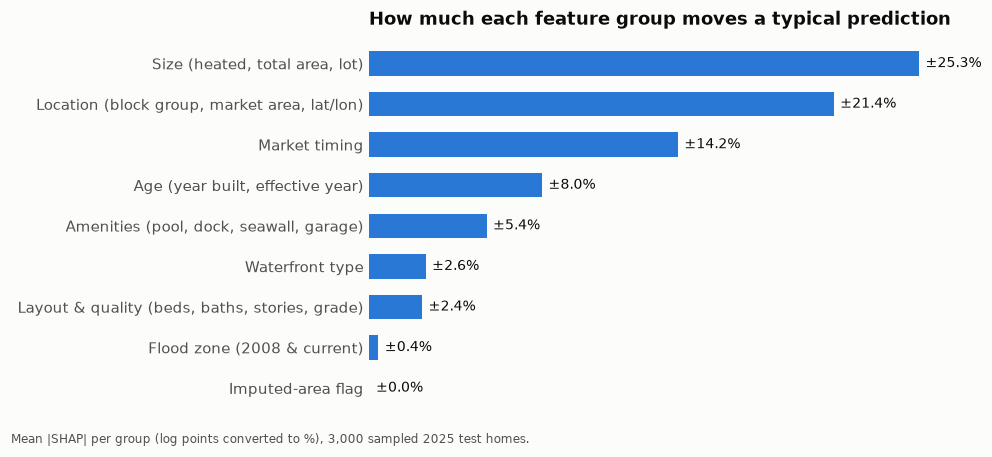

In [11]:
sample = te.sample(3000, random_state=0)
X = gb.features(sample)
sv = shap.TreeExplainer(gb.model)(X)
print("max |sum of SHAP values + base - prediction| =", f"{np.abs(sv.values.sum(1) + sv.base_values - gb.model.predict(X)).max():.1e}")

GROUPS = {
    "Size (heated, total area, lot)": ["log_heated", "log_total", "log_acres"],
    "Location (block group, market area, lat/lon)": ["block_group_te", "market_area_te", "lat", "lon"],
    "Market timing": ["t"],
    "Age (year built, effective year)": ["year_built", "eff_year_built"],
    "Waterfront type": [c for c in X.columns if c.startswith("wf_")],
    "Amenities (pool, dock, seawall, garage)": ["pool", "boat_dock", "seawall", "garage"],
    "Layout & quality (beds, baths, stories, grade)": ["beds", "baths", "stories", "quality", "construction_class"],
    "Flood zone (2008 & current)": ["sfha_2008", "sfha_now"],
    "Imputed-area flag": ["heated_imputed"],
}
sv_df = pd.DataFrame(sv.values, columns=X.columns, index=X.index)
grouped = pd.Series({g: sv_df[cols].sum(axis=1).abs().mean() for g, cols in GROUPS.items()}).sort_values()
pct = lambda v: 100 * (np.exp(v) - 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(range(len(grouped)), pct(grouped), color=C1, height=0.6)
for i, v in enumerate(pct(grouped)):
    ax.text(v + 0.3, i, f"±{v:.1f}%", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(grouped)), grouped.index); ax.tick_params(axis="y", length=0)
ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xticks([])
for s in ["left", "bottom"]: ax.spines[s].set_visible(False)
ax.set_title("How much each feature group moves a typical prediction")
source_note(fig, "Mean |SHAP| per group (log points converted to %), 3,000 sampled 2025 test homes.")
save(fig, FIG / "03_shap_groups.png")

Size and location dominate, as any appraiser would expect. **Market timing** is large because the model
prices every 2025 home at the Dec-2024 market level, well above the 2019–2020 levels in the training data.
**Flood zone contributes almost nothing**, consistent with notebook 02: once location and waterfront are known,
flood-zone status adds little *on average*. (Part 2 asks the sharper question of whether that changed after Ian.)

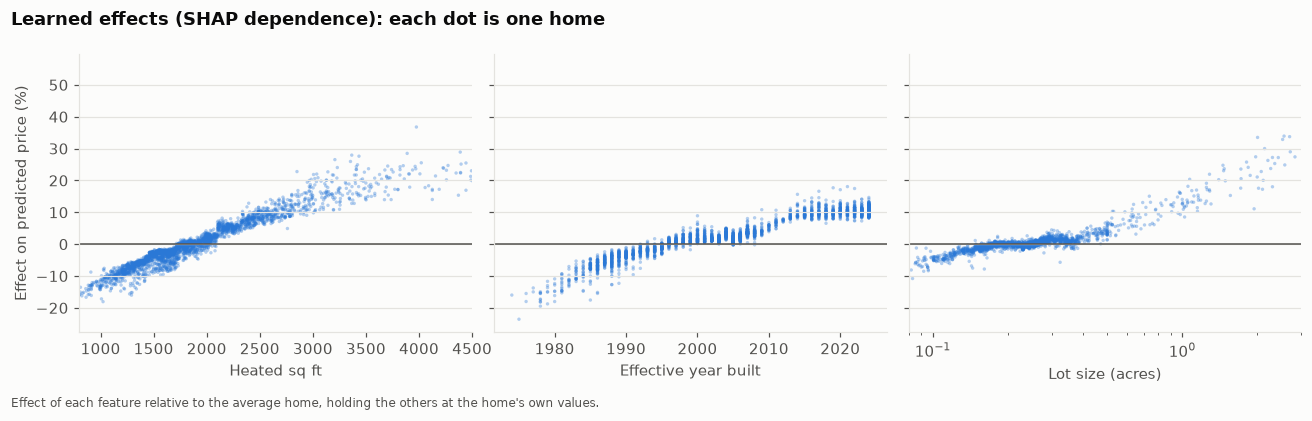

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (feat, label, xf) in zip(axes, [
        ("log_heated", "Heated sq ft", np.exp),
        ("eff_year_built", "Effective year built", lambda v: v),
        ("log_acres", "Lot size (acres)", np.exp)]):
    ax.scatter(xf(X[feat]), pct(sv_df[feat]), s=5, alpha=0.35, color=C1, edgecolor="none")
    ax.axhline(0, color=INK2, lw=1); ax.set_xlabel(label)
    if feat == "log_acres": ax.set_xscale("log"); ax.set_xlim(0.08, 3)
    if feat == "log_heated": ax.set_xlim(800, 4500)
axes[0].set_ylabel("Effect on predicted price (%)")
fig.suptitle("Learned effects (SHAP dependence): each dot is one home", x=0.01, ha="left", fontweight="bold", fontsize=12, color=INK)
source_note(fig, "Effect of each feature relative to the average home, holding the others at the home's own values.")
save(fig, FIG / "03_shap_dependence.png")

**Read:**
- **Heated area:** steady gains, flattening for very large homes.
- **Effective year built:** a steady climb of roughly 20 points from mid-1980s homes to recent ones, with no
  sharp break at 2002. Notebook 02's building-code result was about a *change after Ian*, not the price level.
- **Lot size:** roughly linear on a log scale: each doubling of lot size adds a similar percentage, so
  the dollar value of an extra acre shrinks as lots get bigger.

These shapes are learned without being specified. A linear model would need each one hand-coded.

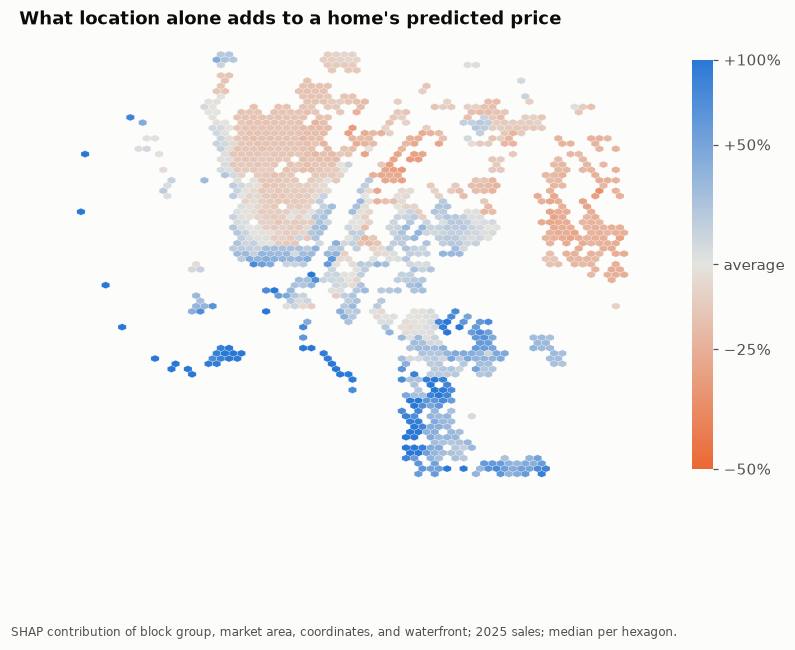

In [13]:
# Location value surface: total SHAP contribution of all location features, mapped
loc_cols = GROUPS["Location (block group, market area, lat/lon)"] + GROUPS["Waterfront type"]
full = te.copy()
Xf = gb.features(full)
svf = shap.TreeExplainer(gb.model)(Xf)
full["loc_effect"] = pd.DataFrame(svf.values, columns=Xf.columns, index=Xf.index)[loc_cols].sum(axis=1)

from matplotlib.colors import TwoSlopeNorm
fig, ax = plt.subplots(figsize=(7.5, 6.5))
hb = ax.hexbin(full["lon"], full["lat"], C=full["loc_effect"], reduce_C_function=np.median, gridsize=70,
               mincnt=3, cmap=DIVERGING, norm=TwoSlopeNorm(0, np.log(0.5), np.log(2)), linewidths=0.15, edgecolors=SURFACE)
cb = fig.colorbar(hb, ax=ax, shrink=0.6, ticks=np.log([0.5, 0.75, 1, 1.5, 2])); cb.outline.set_visible(False)
cb.ax.set_yticklabels(["−50%", "−25%", "average", "+50%", "+100%"])
ax.set_aspect(1 / np.cos(np.radians(26.6))); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("What location alone adds to a home's predicted price")
source_note(fig, "SHAP contribution of block group, market area, coordinates, and waterfront; 2025 sales; median per hexagon.")
save(fig, FIG / "03_location_value_map.png")

This is the model's own "location premium" map: the same house is worth roughly **up to twice the county average on the
Gulf islands and the Bonita/Estero coast**, and around **25–35% less in Lehigh Acres** and the eastern interior. It closely matches the
raw $/sq ft map in notebook 02, but this one holds each home's size, age, and amenities fixed.

## 8. A bridge to Part 2: does the model mis-price flood-zone homes?

If buyers discounted flood risk after Ian in a way the training data didn't capture, a model trained through
2024 would systematically **over-predict** flood-zone homes in 2025.

In [14]:
fz = te.groupby(te["sfha_2008"].map({0.0: "outside flood zone", 1.0: "in flood zone (2008 SFHA)"}))["err"].agg(
    bias_pct=lambda e: 100 * np.median(e), MdAPE=lambda e: 100 * np.median(np.abs(e)), sales="size")
fz.round(2)

,bias_pct,MdAPE,sales
sfha_2008,,,
in flood zone (2008 SFHA),2.85,10.88,4291
outside flood zone,2.90,8.45,7748


**No real bias gap**: both groups are over-predicted by about 3% (the market drift from section 6), within a few
tenths of a point of each other. Flood-zone
homes are *harder* to price (higher MdAPE: more varied waterfront, more storm-affected condition), but not
systematically over-priced. The model trained through 2024 has already absorbed the post-Ian flood-zone discount,
because two years of post-storm sales were in its training data. That's consistent with notebook 02, where the
discount appeared right after the storm and then held roughly steady rather than widening.

## 9. Summary

| | Result (2025 test, forecasting from 2019–2024) |
|---|---|
| Best model | gradient boosting: **~9% median error, ~54% within ±10%, ~80% within ±20%** |
| vs. county appraisal | beats it by ~1 point MdAPE and ~5 points PPE10 using only public data |
| vs. comps rule of thumb | cuts the median error from ~16% to ~9% |
| Biggest drivers | size, location, market timing; then age and water |
| Main weakness | market drift (bias grows through 2025) and cheap / rare waterfront homes |

**Methodological points worth knowing:**
1. Time-based split with a frozen market clock (a random split overstates accuracy).
2. Appraised value is a strong standalone benchmark but a poor feature, because its lag behind the market
   varies year to year (1.18–1.52×).
3. SHAP values were verified to sum to predictions, which caught a real bug in SHAP's handling of categorical splits.

**Next, Phase 5 (Part 2):** the formal difference-in-differences for Hurricane Ian: matching flood-zone
homes to comparable non-flood-zone homes, robustness to the 2020–21 pre-trend drift, separating Ian from
Helene/Milton, and the damaged-sale question.